# Task 4.1 - CNN
Goal: Build a CNN to predict which class the image from the dataset belongs to, figuring out what each dinosaur should be fed.    
Deadline: 1st February

In [18]:
import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt

import os
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

## Data Loading and Preprocessing

- Images are loaded from class-specific folders
- Converted to grayscale
- Resized to 64×64
- Normalized to [0,1]

In [19]:
def load_images_from_folder(base_path, class_to_label, img_size=(64, 64)):
    X = []
    Y = []

    for class_name, label in class_to_label.items():
        class_folder = os.path.join(base_path, class_name)

        for file in os.listdir(class_folder):
            img_path = os.path.join(class_folder, file)

            # Read image in grayscale
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

            if img is None:
                continue  # skip corrupted files

            # Resize
            img = cv2.resize(img, img_size)

            X.append(img)
            Y.append(label)

    return np.array(X), np.array(Y)

In [20]:
class_to_label = {
    "Apatosaur Aphie's Apples": 0,
    "Bluplocephalus Bob's Blueberries": 1,
    "Cherizinoasaur Cher's Cherries": 2,
    "Corythosaurus Cory's Corn": 3,
    "Grapthorina Greta's Grapes": 4,
    "Pachycephalosaurus Perry's Peaches": 5,
    "Pepteranodon Pep's Peppers": 6,
    "Potoceratops Pott's Potatoes": 7,
    "Rhaspdodon Ribery's Raspberries": 8,
    "Stribecosaurus Stan's Strawberries": 9,
    "Thyreosaur Tim's Thyme": 10,
    "vacation_photos": 11
}

X_train, Y_train = load_images_from_folder("data/veggie_heap_training/", class_to_label)
X_test, Y_test = load_images_from_folder("data/veggie_heap_testing", class_to_label)

In [21]:
#Adding a new channel dimension
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]
#Checking shape 
print("Train X shape:", X_train.shape)
print("Train Y shape:", Y_train.shape)
print("Test X shape:", X_test.shape)
print("Test Y shape:", Y_test.shape)
print("Unique labels:", np.unique(Y_train))

Train X shape: (9835, 64, 64, 1)
Train Y shape: (9835,)
Test X shape: (2424, 64, 64, 1)
Test Y shape: (2424,)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11]


In [22]:
#Normalizing pixel values to prevent exploding gradients
X_train = X_train / 255.0
X_test = X_test / 255.0

In [23]:
#Checking for class imbalance
class_names = list(class_to_label.keys())
unique, counts = np.unique(Y_train, return_counts=True)

for u, c in zip(unique, counts):
    print(f"{class_names[u]}: {c}")

Apatosaur Aphie's Apples: 1445
Bluplocephalus Bob's Blueberries: 1302
Cherizinoasaur Cher's Cherries: 654
Corythosaurus Cory's Corn: 945
Grapthorina Greta's Grapes: 423
Pachycephalosaurus Perry's Peaches: 360
Pepteranodon Pep's Peppers: 1478
Potoceratops Pott's Potatoes: 152
Rhaspdodon Ribery's Raspberries: 249
Stribecosaurus Stan's Strawberries: 306
Thyreosaur Tim's Thyme: 1591
vacation_photos: 930


## Dataset Preparation

- Data converted to PyTorch tensors
- Train-validation split applied (80-20)
- DataLoader used for batching and shuffling

In [24]:
# Convert to Pytorch Format

X_train_torch = torch.tensor(X_train, dtype=torch.float32).permute(0, 3, 1, 2)
X_test_torch = torch.tensor(X_test, dtype=torch.float32).permute(0, 3, 1, 2)

Y_train_torch = torch.tensor(Y_train, dtype=torch.long)
Y_test_torch = torch.tensor(Y_test, dtype=torch.long)

print("Train X shape:", X_train_torch.shape)
print("Train Y shape:", Y_train_torch.shape)
print("Test X shape:", X_test_torch.shape)
print("Test Y shape:", Y_test_torch.shape)

Train X shape: torch.Size([9835, 1, 64, 64])
Train Y shape: torch.Size([9835])
Test X shape: torch.Size([2424, 1, 64, 64])
Test Y shape: torch.Size([2424])


In [25]:
# Create DataLoader

train_dataset = TensorDataset(X_train_torch, Y_train_torch)
test_dataset = TensorDataset(X_test_torch, Y_test_torch)

train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

## Model Architecture

The CNN consists of:
- 3 Convolutional layers for feature extraction
- MaxPooling layers for downsampling
- Fully connected layers for classification

In [26]:
# Define CNN model

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, 3)    # feature extraction
        self.conv2 = nn.Conv2d(32, 64, 3)   # deeper features
        self.conv3 = nn.Conv2d(64, 128, 3)  # complex patterns

        self.pool = nn.MaxPool2d(2,2)

        self.fc1 = nn.Linear(128 * 6 * 6, 64)  # reasoning layer
        self.fc2 = nn.Linear(64, 12)           # classification

        #self.dropout = nn.Dropout(0.5)

    def forward(self, X):
        X = self.pool(F.relu(self.conv1(X)))    # (32, 31, 31)
        X = self.pool(F.relu(self.conv2(X)))    # (64, 14, 14)
        X = self.pool(F.relu(self.conv3(X)))    # (128, 6, 6)

        X = X.view(X.size(0), -1)

        X = F.relu(self.fc1(X))
        #X = self.dropout(X)
        X = self.fc2(X)

        return X

## Training Process

- Loss Function: CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Epochs: 10

In [27]:
# Training setup

model = CNN()

#criterion = nn.CrossEntropyLoss()
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(Y_train),
    y=Y_train
)

class_weights = torch.tensor(class_weights, dtype=torch.float32)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [28]:
# Training Loop

epochs = 10
train_accs = []
val_accs = []

for epoch in range(epochs):

    # TRAINING
    model.train()
    correct = 0
    total = 0
    running_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = correct / total

    # VALIDATION 
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = val_correct / val_total

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

Epoch 1, Train Acc: 0.4513, Val Acc: 0.6009
Epoch 2, Train Acc: 0.7045, Val Acc: 0.6782
Epoch 3, Train Acc: 0.7799, Val Acc: 0.7331
Epoch 4, Train Acc: 0.8407, Val Acc: 0.8363
Epoch 5, Train Acc: 0.8658, Val Acc: 0.8719
Epoch 6, Train Acc: 0.8953, Val Acc: 0.8699
Epoch 7, Train Acc: 0.9089, Val Acc: 0.8851
Epoch 8, Train Acc: 0.9287, Val Acc: 0.8765
Epoch 9, Train Acc: 0.9389, Val Acc: 0.8856
Epoch 10, Train Acc: 0.9478, Val Acc: 0.8988


## Model Evaluation

The model is evaluated using:
- Test Accuracy
- Confusion Matrix
- Sample Predictions

In [29]:
# Evaluation

all_preds = []
all_labels = []

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_preds.extend(predicted.numpy())
        all_labels.extend(labels.numpy())

print("Test Accuracy:", correct / total)

Test Accuracy: 0.6039603960396039


In [30]:
print(classification_report(all_labels, all_preds, target_names=class_names))

f1 = f1_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
precision = precision_score(all_labels, all_preds, average='macro')

print("F1 (macro):", f1)
print("Recall (macro):", recall)
print("Precision (macro):", precision)

                                    precision    recall  f1-score   support

          Apatosaur Aphie's Apples       0.27      0.88      0.41       200
  Bluplocephalus Bob's Blueberries       0.82      0.87      0.84       200
    Cherizinoasaur Cher's Cherries       0.98      0.88      0.93       200
         Corythosaurus Cory's Corn       0.83      0.96      0.89       217
        Grapthorina Greta's Grapes       0.84      0.31      0.45       150
Pachycephalosaurus Perry's Peaches       0.27      0.15      0.19       199
        Pepteranodon Pep's Peppers       0.51      0.41      0.46       200
      Potoceratops Pott's Potatoes       0.51      0.36      0.42       200
   Rhaspdodon Ribery's Raspberries       0.70      0.84      0.76       122
Stribecosaurus Stan's Strawberries       0.80      0.88      0.84       150
            Thyreosaur Tim's Thyme       0.69      0.28      0.39       373
                   vacation_photos       0.82      0.77      0.79       213

          

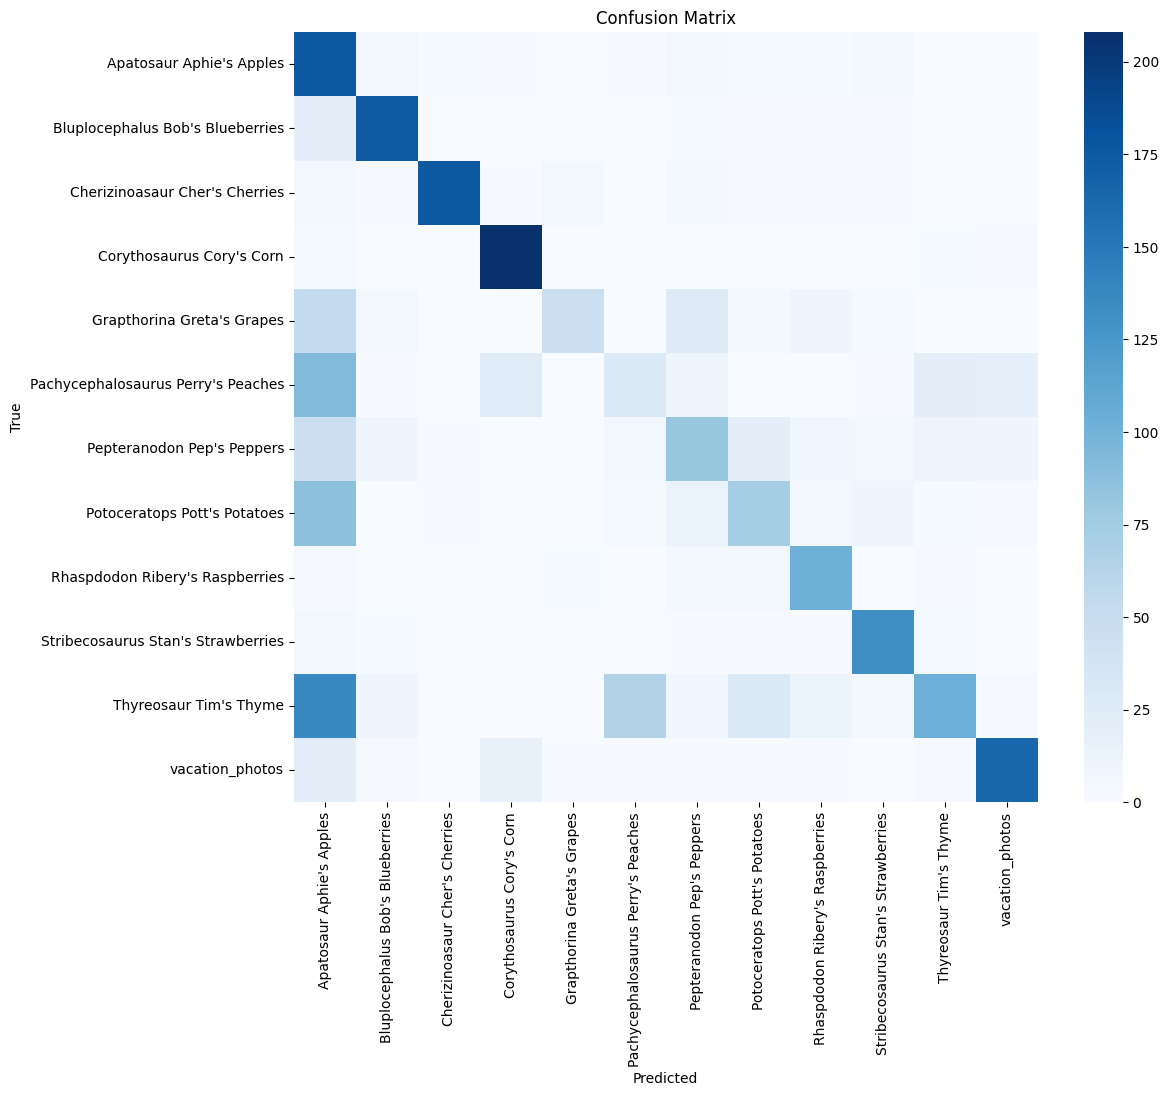

In [31]:
# Confusion Matrix

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=False, cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

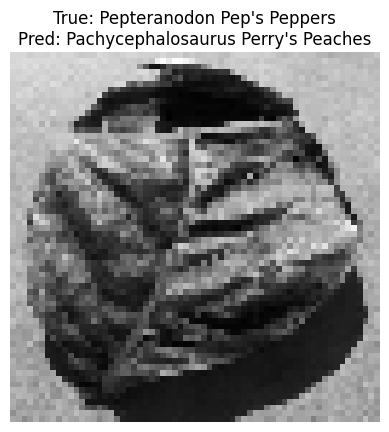

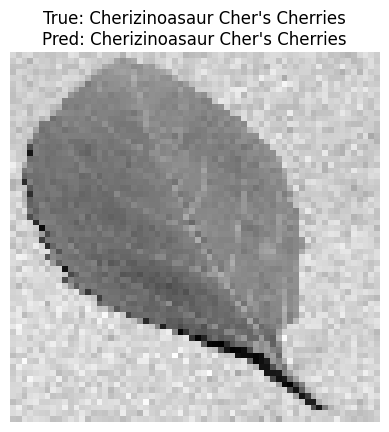

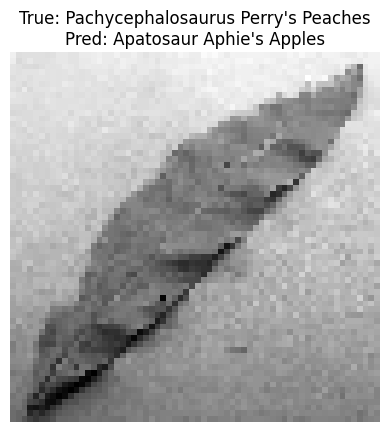

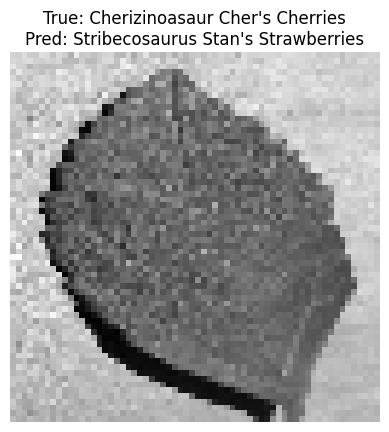

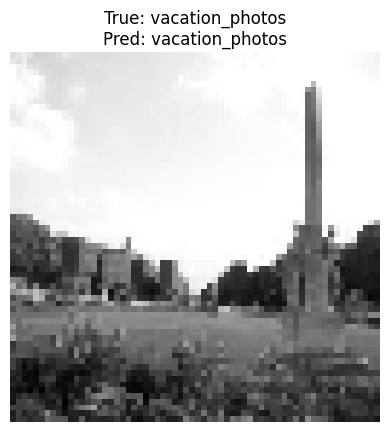

In [32]:
# Prediction Visualization

for _ in range(5):
    idx = random.randint(0, len(X_test_torch)-1)
    
    image = X_test_torch[idx]
    label = Y_test[idx]

    with torch.no_grad():
        output = model(image.unsqueeze(0))
        _, pred = torch.max(output, 1)

    plt.imshow(image.squeeze(), cmap='gray')
    plt.title(f"True: {class_names[label]}\nPred: {class_names[pred.item()]}")
    plt.axis('off')
    plt.show()

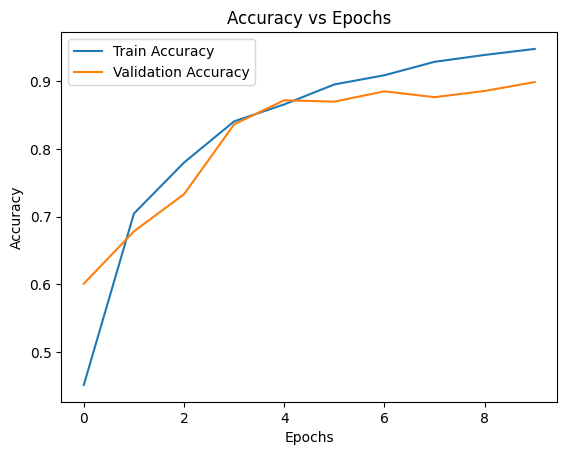

In [33]:
# Training Graphs

plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Epochs")
plt.show()

## Final Results and Conclusion

### Model Performance
The Convolutional Neural Network (CNN) was trained to classify 64×64 grayscale images into 12 categories (11 food classes + 1 vacation class). 

- Final Training Accuracy: ~95%
- Final Validation Accuracy: ~90–91%
- Test Accuracy: **63.7%**

The model demonstrates strong learning on the training and validation sets, with a moderate drop in test accuracy, indicating some generalization gap but overall reasonable performance.

---

### Effect of Adding Vacation Class
Initially, the model was trained on 11 classes. A 12th class ("vacation photos") was introduced to handle images that do not belong to any food category.

This resulted in:
- Improvement in test accuracy (from ~62% → ~63.7%)
- Better handling of out-of-distribution images

The confusion matrix shows that:
- Vacation images are mostly classified correctly
- The model does not excessively misclassify food images as vacation

This indicates that the model successfully learned a meaningful separation between relevant and irrelevant inputs.

---

### Observations from Confusion Matrix
- Strong performance on visually distinct classes such as apples, corn, thyme, and blueberries
- Misclassifications occur mainly between visually similar categories:
  - Grapes, peaches, and apples
  - Peppers and potatoes

This suggests that grayscale images limit the model’s ability to capture fine texture and color differences.

---

### Limitations
- Use of grayscale images reduces feature richness
- Some classes have high visual similarity, making separation difficult
- Moderate gap between validation and test accuracy

---

### Possible Improvements
- Use RGB images instead of grayscale
- Apply data augmentation (rotation, flipping, scaling)
- Tune hyperparameters (learning rate, batch size, epochs)
- Use deeper architectures or transfer learning (e.g., pretrained models)

---

### Final Conclusion
The CNN model is able to learn meaningful patterns from the dataset and achieves reasonable classification performance. The introduction of a "vacation" class improved robustness by allowing the model to handle unrelated inputs more effectively.

Overall, the model demonstrates a good balance between learning capacity and generalization, while also highlighting areas for further improvement.

### Personal Notes
* (N,C,H,W)->expected shape for input in pytorch (C=channel)
* No need for one hot encoding since pytorch expects integer labels since we are using nn.CrossEntopyLoss() which already:
    1. Applies Softmax
    2. Computes Cross-Entropy Loss 
* So, model output will also be raw logits[NO Softmax], since nn.CrossEntopyLoss() handles that 
* Dataloader(Pytorch Concept): Used for processing data samples. Handles:
    1. Batching (Dividing samples into batches) 
    2. Shuffling (Prevents learning order-based patters) 
    3. Results in efficient memory usage + Doesn't overload RAM/GPU + cleaner training loop
* Adding a 12th class improved model robustness
* Struggles with similar classes (apple <-> peaches) -> identified using confusion matrix